In [10]:
# loading the libraries
import pyfesom2 as pf
import matplotlib.pylab as plt
import xarray as xr
import numpy as np
import matplotlib.tri as mtri
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import time
from matplotlib.path import Path
import pandas as pd
import os
import gc
from matplotlib.colors import TwoSlopeNorm
from dask.diagnostics import ProgressBar
from tqdm.auto import tqdm
from pathlib import Path as FilePath
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

In [2]:
# loading the mesh
meshpath = '/albedo/work/projects/p_trr181/ebagaeva/work/ebagaeva/3IGW/Meshes/farc/'
alpha, beta, gamma=[0, 0, 0]
mesh=pf.load_mesh(meshpath, abg=[alpha, beta, gamma], usepickle = False, usejoblib=True)


The usejoblib == True)
The joblib file for FESOM2 exists.
The mesh will be loaded from /albedo/work/projects/p_trr181/ebagaeva/work/ebagaeva/3IGW/Meshes/farc/joblib_mesh_fesom2


In [3]:
# paths to the data

YEAR = 2014
LAT_MIN = 65

BASE_AWICM = FilePath(
    "/albedo/work/projects/p_trr181/ebagaeva/work/"
    "ebagaeva/3IGW/AWICM"
)

BASE_JRA55 = FilePath(
    "/albedo/work/projects/p_trr181/ebagaeva/work/"
    "ebagaeva/3IGW/JRA55_2014"
)

EXPERIMENTS = {
    "jra55": {
        "ref": BASE_JRA55 / "No_tides_2014",
        "tides": BASE_JRA55 / "Tides_2014",
    },
    "awicm": {
        "ref": BASE_AWICM / "L_no_tides_2014",
        "tides": BASE_AWICM / "L_tides_2014",
    },
}

SAVE_DATA = FilePath("./processed_data/SST_SSS_2014")
SAVE_DATA.mkdir(parents=True, exist_ok=True)

print("Saving results to:", SAVE_DATA.resolve())

Saving results to: /albedo/work/projects/p_trr181/ebagaeva/home/3IGW/Python scripts/!Clean plots/processed_data/SST_SSS_2014


In [4]:
#function to load surface temperature or salinity

def load_surface(path, variable, label):

    if variable == "sss":
        surface_var = "sss"
        volume_var = "salt"

    elif variable == "sst":
        surface_var = "sst"
        volume_var = "temp"

    else:
        raise ValueError("variable must be 'sss' or 'sst'")

    surface_file = path / f"{surface_var}.fesom.{YEAR}.nc"
    volume_file = path / f"{volume_var}.fesom.{YEAR}.nc"

    if surface_file.exists():

        print(f"{label}: loading {surface_var.upper()}")

        ds = xr.open_dataset(
            surface_file,
            chunks={"time": 10}
        )

        da = ds[surface_var]

    elif volume_file.exists():

        print(f"{label}: loading surface {volume_var}")

        ds = xr.open_dataset(
            volume_file,
            chunks={"time": 10}
        )

        da = ds[volume_var].isel(nz1=0)

    else:
        raise FileNotFoundError(
            f"No {surface_var} or {volume_var} file in {path}"
        )

    if da.ndim != 2:
        ds.close()
        raise ValueError(
            f"{label}: unexpected dimensions {da.dims}"
        )

    if da.sizes["nod2"] != len(mesh.y2):
        ds.close()
        raise ValueError(
            f"{label}: node count does not match mesh"
        )

    print(f"\n{label}")
    print("Shape:", da.shape)
    print("First date:", da.time.values[0])
    print("Last date: ", da.time.values[-1])

    return da, ds

In [5]:
# calculate annual mean tidal effect

def calculate_difference(forcing, variable):

    print("\n" + "=" * 60)
    print(f"{forcing.upper()} | {variable.upper()} | {YEAR}")
    print("=" * 60)

    paths = EXPERIMENTS[forcing]

    s_ref = None
    s_tides = None
    ds_ref = None
    ds_tides = None

    try:
        # ====================================================
        # LOAD DATA
        # ====================================================

        s_ref, ds_ref = load_surface(
            paths["ref"],
            variable,
            "NO TIDES"
        )

        s_tides, ds_tides = load_surface(
            paths["tides"],
            variable,
            "TIDES"
        )

        # ====================================================
        # ALIGN COMMON DAILY SNAPSHOTS
        # ====================================================

        times_ref_all = pd.DatetimeIndex(
            s_ref.time.values
        )

        times_tides_all = pd.DatetimeIndex(
            s_tides.time.values
        )

        if not times_ref_all.is_unique:
            raise ValueError("NO TIDES has duplicate timestamps")

        if not times_tides_all.is_unique:
            raise ValueError("TIDES has duplicate timestamps")

        start = pd.Timestamp(f"{YEAR}-01-01")
        end = pd.Timestamp(f"{YEAR + 1}-01-01")

        times_ref = times_ref_all[
            (times_ref_all >= start)
            & (times_ref_all < end)
        ]

        times_tides = times_tides_all[
            (times_tides_all >= start)
            & (times_tides_all < end)
        ]

        common = (
            times_ref.intersection(times_tides)
            .sort_values()
        )

        expected_days = (
            366 if start.is_leap_year else 365
        )

        print("\nDAILY COVERAGE")
        print("NO TIDES:", len(times_ref))
        print("TIDES:   ", len(times_tides))
        print("COMMON:  ", len(common))
        print("EXPECTED:", expected_days)

        if len(common) == 0:
            raise ValueError("No common timestamps")

        if len(common) != expected_days:
            print("WARNING: Incomplete daily coverage")

        if pd.DatetimeIndex(common).normalize().has_duplicates:
            raise ValueError("Multiple snapshots per day")

        s_ref = s_ref.sel(time=common)
        s_tides = s_tides.sel(time=common)

        # ====================================================
        # CALCULATE MEANS — ORIGINAL METHOD
        # ====================================================

        print("\nComputing NO TIDES mean")

        with ProgressBar():
            ref_mean = (
                s_ref.mean(
                    dim="time",
                    skipna=True
                )
                .compute()
                .values
            )

        print("\nComputing TIDES mean")

        with ProgressBar():
            tides_mean = (
                s_tides.mean(
                    dim="time",
                    skipna=True
                )
                .compute()
                .values
            )

        diff_mean = tides_mean - ref_mean

        # ====================================================
        # SAVE RESULT
        # ====================================================

        output_file = (
            SAVE_DATA
            / f"diff_{forcing}_{variable}_{YEAR}.npy"
        )

        np.save(output_file, diff_mean.astype(np.float32))

        print("\nSaved:", output_file)
        print("Shape:", diff_mean.shape)

        # ====================================================
        # ARCTIC STATISTICS
        # ====================================================

        lat = np.asarray(mesh.y2)
        mask = lat >= LAT_MIN

        diff_arctic = diff_mean[mask]

        print(
            "Arctic 5th, 50th, 95th percentiles:",
            np.nanpercentile(
                diff_arctic,
                [5, 50, 95]
            )
        )

        return diff_mean.astype(np.float32)

    finally:

        if ds_ref is not None:
            ds_ref.close()

        if ds_tides is not None:
            ds_tides.close()

        gc.collect()

In [6]:
# JRA55, sss

diff_jra55_sss = calculate_difference(
    "jra55", "sss"
)


JRA55 | SSS | 2014
NO TIDES: loading surface salt

NO TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000
TIDES: loading surface salt

TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000

DAILY COVERAGE
NO TIDES: 365
TIDES:    365
COMMON:   365
EXPECTED: 365

Computing NO TIDES mean
[########################################] | 100% Completed | 199.40 s

Computing TIDES mean
[########################################] | 100% Completed | 198.91 s

Saved: processed_data/SST_SSS_2014/diff_jra55_sss_2014.npy
Shape: (638387,)
Arctic 5th, 50th, 95th percentiles: [-0.19416429 -0.00844838  0.34410587]


In [7]:
# AWICM, sss

diff_awicm_sss = calculate_difference(
    "awicm", "sss"
)


AWICM | SSS | 2014
NO TIDES: loading surface salt

NO TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000
TIDES: loading surface salt

TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000

DAILY COVERAGE
NO TIDES: 365
TIDES:    365
COMMON:   365
EXPECTED: 365

Computing NO TIDES mean
[########################################] | 100% Completed | 200.71 s

Computing TIDES mean
[########################################] | 100% Completed | 198.92 s

Saved: processed_data/SST_SSS_2014/diff_awicm_sss_2014.npy
Shape: (638387,)
Arctic 5th, 50th, 95th percentiles: [-0.24556161  0.08153223  0.61833321]


In [8]:
# JRA55, sst

diff_jra55_sst = calculate_difference(
    "jra55", "sst"
)


JRA55 | SST | 2014
NO TIDES: loading surface temp

NO TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000
TIDES: loading surface temp

TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000

DAILY COVERAGE
NO TIDES: 365
TIDES:    365
COMMON:   365
EXPECTED: 365

Computing NO TIDES mean
[########################################] | 100% Completed | 157.74 s

Computing TIDES mean
[########################################] | 100% Completed | 161.64 s

Saved: processed_data/SST_SSS_2014/diff_jra55_sst_2014.npy
Shape: (638387,)
Arctic 5th, 50th, 95th percentiles: [-0.18267055  0.0005573   0.15723722]


In [9]:
# AWICM, sst

diff_awicm_sst = calculate_difference(
    "awicm", "sst"
)


AWICM | SST | 2014
NO TIDES: loading surface temp

NO TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000
TIDES: loading surface temp

TIDES
Shape: (365, 638387)
First date: 2014-01-01T23:55:00.000000000
Last date:  2014-12-31T23:55:00.000000000

DAILY COVERAGE
NO TIDES: 365
TIDES:    365
COMMON:   365
EXPECTED: 365

Computing NO TIDES mean
[########################################] | 100% Completed | 156.72 s

Computing TIDES mean
[########################################] | 100% Completed | 158.38 s

Saved: processed_data/SST_SSS_2014/diff_awicm_sst_2014.npy
Shape: (638387,)
Arctic 5th, 50th, 95th percentiles: [-0.20156802 -0.00359142  0.19432551]


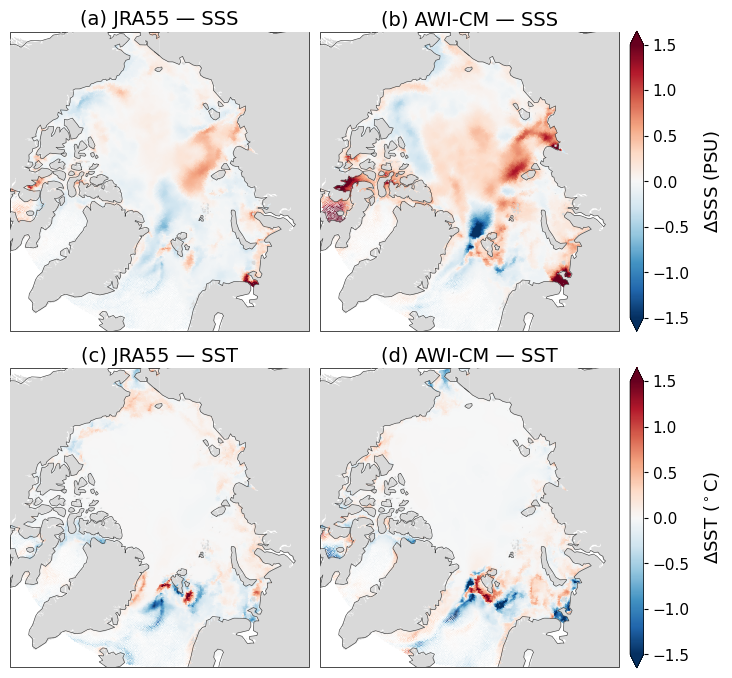

PNG: /albedo/work/projects/p_trr181/ebagaeva/home/3IGW/Python scripts/!Clean plots/figures/SST_SSS_Forcing_Comparison/SSS_SST_JRA55_AWICM_2014_JPO_compact.png
PDF: /albedo/work/projects/p_trr181/ebagaeva/home/3IGW/Python scripts/!Clean plots/figures/SST_SSS_Forcing_Comparison/SSS_SST_JRA55_AWICM_2014_JPO_compact.pdf


In [13]:

# ============================================================
# PLotting: TIDAL EFFECT ON SSS AND SST

# ============================================================
# ============================================================
# 1. SETTINGS
# ============================================================

YEAR = 2014
LAT_MIN = 65.0

SSS_LIMIT = 1.5
SST_LIMIT = 1.5

DATA_DIR = FilePath("./processed_data/SST_SSS_2014")

SAVE_DIR = FilePath(
    "./figures/SST_SSS_Forcing_Comparison"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

FIGSIZE = (7, 7)

FS_PANEL = 14
FS_CBAR_LABEL = 13
FS_CBAR_TICKS = 11

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": FS_PANEL,
    "axes.linewidth": 0.5,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# 2. LOAD SAVED ARRAYS
# ============================================================

diff_jra55_sss = np.load(
    DATA_DIR / "diff_jra55_sss_2014.npy"
)

diff_awicm_sss = np.load(
    DATA_DIR / "diff_awicm_sss_2014.npy"
)

diff_jra55_sst = np.load(
    DATA_DIR / "diff_jra55_sst_2014.npy"
)

diff_awicm_sst = np.load(
    DATA_DIR / "diff_awicm_sst_2014.npy"
)

# ============================================================
# 3. ARCTIC MASK
# ============================================================

lon = np.asarray(mesh.x2)
lat = np.asarray(mesh.y2)

mask = lat >= LAT_MIN

lon_a = lon[mask]
lat_a = lat[mask]

fields = [
    diff_jra55_sss[mask],
    diff_awicm_sss[mask],
    diff_jra55_sst[mask],
    diff_awicm_sst[mask],
]

for name, arr in zip(
    [
        "JRA55 SSS",
        "AWI-CM SSS",
        "JRA55 SST",
        "AWI-CM SST",
    ],
    fields
):
    if arr.shape != lon_a.shape:
        raise ValueError(
            f"{name}: incompatible shape {arr.shape}"
        )

# ============================================================
# 4. COLOR SCALES
# ============================================================

norm_sss = TwoSlopeNorm(
    vmin=-SSS_LIMIT,
    vcenter=0,
    vmax=SSS_LIMIT
)

norm_sst = TwoSlopeNorm(
    vmin=-SST_LIMIT,
    vcenter=0,
    vmax=SST_LIMIT
)

norms = [
    norm_sss,
    norm_sss,
    norm_sst,
    norm_sst,
]

titles = [
    "(a) JRA55 — SSS",
    "(b) AWI-CM — SSS",
    "(c) JRA55 — SST",
    "(d) AWI-CM — SST",
]

cmap = "RdBu_r"

# ============================================================
# 5. COMPACT FIGURE LAYOUT
# ============================================================

fig = plt.figure(figsize=FIGSIZE)

# 2 rows, 3 columns:
# two maps + narrow colorbar column
gs = fig.add_gridspec(
    nrows=2,
    ncols=3,
    width_ratios=[1, 1, 0.045],
    height_ratios=[1, 1],
    left=0.035,
    right=0.94,
    bottom=0.055,
    top=0.965,
    wspace=0.055,
    hspace=0.12
)

projection = ccrs.NorthPolarStereo()

axes = np.empty((2, 2), dtype=object)

for row in range(2):
    for col in range(2):
        axes[row, col] = fig.add_subplot(
            gs[row, col],
            projection=projection
        )

cax_sss = fig.add_subplot(gs[0, 2])
cax_sst = fig.add_subplot(gs[1, 2])

# ============================================================
# 6. DRAW FOUR MAPS
# ============================================================

for ax, field, title, norm in zip(
    axes.flat,
    fields,
    titles,
    norms
):

    ax.set_extent(
        [-180, 180, LAT_MIN, 90],
        crs=ccrs.PlateCarree()
    )

    ax.scatter(
        lon_a,
        lat_a,
        c=np.ma.masked_invalid(field),
        s=0.65,
        cmap=cmap,
        norm=norm,
        transform=ccrs.PlateCarree(),
        rasterized=True,
        linewidths=0,
        zorder=2
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="0.85",
        edgecolor="none",
        zorder=5
    )

    ax.coastlines(
        resolution="110m",
        linewidth=0.45,
        color="0.25",
        zorder=6
    )

    ax.set_title(
        title,
        fontsize=FS_PANEL,
        pad=5
    )

# ============================================================
# 7. VERTICAL COLORBAR — SSS (TOP ROW)
# ============================================================

sm_sss = ScalarMappable(
    norm=norm_sss,
    cmap=cmap
)
sm_sss.set_array([])

cbar_sss = fig.colorbar(
    sm_sss,
    cax=cax_sss,
    orientation="vertical",
    extend="both"
)

cbar_sss.set_label(
    r"$\Delta$SSS (PSU)",
    fontsize=FS_CBAR_LABEL,
    labelpad=9
)

cbar_sss.set_ticks(
    np.arange(-SSS_LIMIT, SSS_LIMIT + 0.01, 0.5)
)

cbar_sss.ax.tick_params(
    labelsize=FS_CBAR_TICKS,
    length=3
)

# ============================================================
# 8. VERTICAL COLORBAR — SST (BOTTOM ROW)
# ============================================================

sm_sst = ScalarMappable(
    norm=norm_sst,
    cmap=cmap
)
sm_sst.set_array([])

cbar_sst = fig.colorbar(
    sm_sst,
    cax=cax_sst,
    orientation="vertical",
    extend="both"
)

cbar_sst.set_label(
    r"$\Delta$SST ($^\circ$C)",
    fontsize=FS_CBAR_LABEL,
    labelpad=9
)

cbar_sst.set_ticks(
    np.arange(-SST_LIMIT, SST_LIMIT + 0.01, 0.5)
)

cbar_sst.ax.tick_params(
    labelsize=FS_CBAR_TICKS,
    length=3
)

# ============================================================
# 9. SAVE FIGURE
# ============================================================

png_path = SAVE_DIR / (
    f"SSS_SST_JRA55_AWICM_{YEAR}_JPO_compact.png"
)

pdf_path = SAVE_DIR / (
    f"SSS_SST_JRA55_AWICM_{YEAR}_JPO_compact.pdf"
)

fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight",
    pad_inches=0.04,
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.04,
    facecolor="white"
)

plt.show()

print("PNG:", png_path.resolve())
print("PDF:", pdf_path.resolve())
